In [66]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import plotly.express as px

In [67]:
df = pd.read_csv('pizza_sales.csv')


In [68]:
df.isnull().sum()

pizza_id             0
order_id             0
pizza_name_id        0
quantity             0
order_date           0
order_time           0
unit_price           0
total_price          0
pizza_size           0
pizza_category       0
pizza_ingredients    0
pizza_name           0
dtype: int64

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  int64  
 1   order_id           48620 non-null  int64  
 2   pizza_name_id      48620 non-null  object 
 3   quantity           48620 non-null  int64  
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48620 non-null  object 
 10  pizza_ingredients  48620 non-null  object 
 11  pizza_name         48620 non-null  object 
dtypes: float64(2), int64(3), object(7)
memory usage: 4.5+ MB


In [70]:
def dateConverter(dataframe, *args):
    for col in args:
        dataframe[col] = pd.to_datetime(dataframe[col], format='mixed')

dateConverter(df,'order_date','order_time')

In [71]:
df.columns

Index(['pizza_id', 'order_id', 'pizza_name_id', 'quantity', 'order_date',
       'order_time', 'unit_price', 'total_price', 'pizza_size',
       'pizza_category', 'pizza_ingredients', 'pizza_name'],
      dtype='object')

In [72]:
df['Order_Day'] = df['order_date'].dt.day_name()
df['Order_Month'] = df['order_date'].dt.month_name()
df['Order_Hour'] = df['order_date'].dt.hour

weekdays = ['Sunday','Monday','Tuesday','Wednesday','Thursday','Friday','Saturday']
df['Order_Day'] = pd.Categorical(df['Order_Day'], categories=weekdays)

months = ['January', 'February','March','April','May','June','July',
          'August','September','October','November','December']
df['Order_Month'] = pd.Categorical(df['Order_Month'], categories = months)

sales = df.groupby('Order_Day', observed=False)['total_price'].sum().reset_index()
sales

,Order_Day,total_price
0,Sunday,102116.45
1,Monday,110471.60
2,Tuesday,115594.45
3,Wednesday,116731.20
4,Thursday,121650.30
5,Friday,129690.90
6,Saturday,121605.15


In [73]:
monthly_sales = df.groupby('Order_Month', observed=False)['total_price'].sum().reset_index()
monthly_sales

,Order_Month,total_price
0,January,71620.15
1,February,64419.45
2,March,71301.40
3,April,70312.00
4,May,67648.80
5,June,68161.45
6,July,70880.65
7,August,69497.30
8,September,63803.70
9,October,68152.20


# Pie Chart

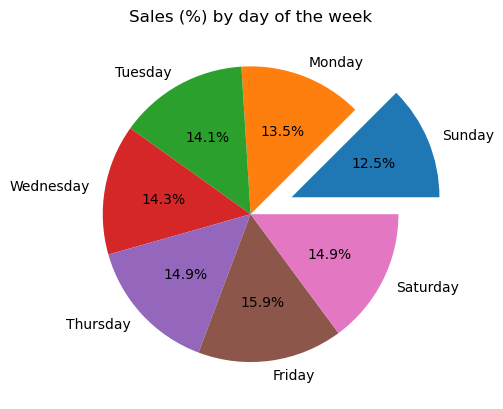

In [74]:
plt.pie(
    sales['total_price'],
    labels = sales['Order_Day'],
    autopct = '%1.1f%%',
    explode=(0.3,0,0,0,0,0,0)
)
plt.title('Sales (%) by day of the week')
plt.show()

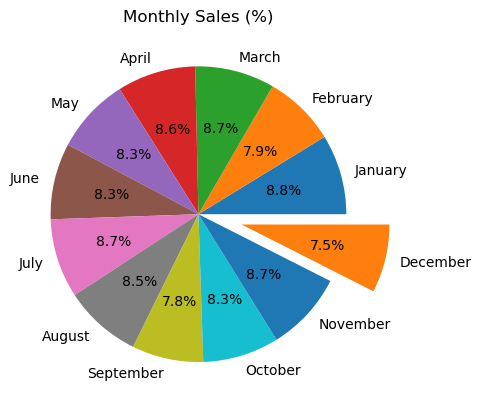

In [75]:
plt.pie(
    monthly_sales['total_price'],
    labels = monthly_sales['Order_Month'],
    autopct = '%1.1f%%',
    explode=(0,0,0,0,0,0,0,0,0,0,0,0.3)
)
plt.title('Monthly Sales (%)')
plt.show()

# Donut Chart

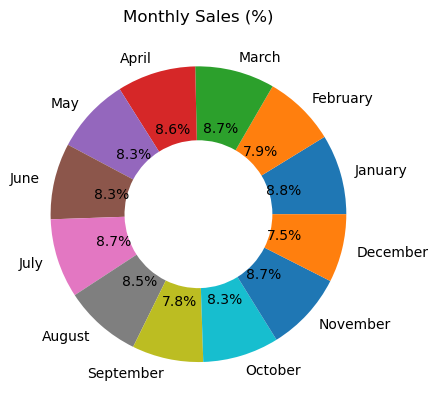

In [76]:
plt.pie(
    monthly_sales['total_price'],
    labels = monthly_sales['Order_Month'],
    autopct = '%1.1f%%',
    wedgeprops={'width':0.5},
)
plt.title('Monthly Sales (%)')
plt.show()

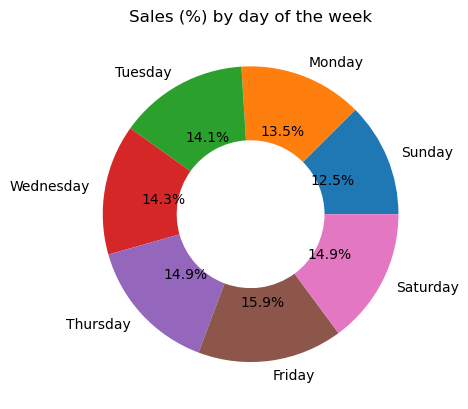

In [77]:
plt.pie(
    sales['total_price'],
    labels = sales['Order_Day'],
    autopct = '%1.1f%%',
    wedgeprops={'width':0.5},
)
plt.title('Sales (%) by day of the week')
plt.show()

In [78]:
df.columns

Index(['pizza_id', 'order_id', 'pizza_name_id', 'quantity', 'order_date',
       'order_time', 'unit_price', 'total_price', 'pizza_size',
       'pizza_category', 'pizza_ingredients', 'pizza_name', 'Order_Day',
       'Order_Month', 'Order_Hour'],
      dtype='object')

In [79]:
per = df.groupby(['Order_Day','pizza_size'])['quantity'].sum().reset_index()
per

C:\Users\Acer\AppData\Local\Temp\ipykernel_8988\192048542.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per = df.groupby(['Order_Day','pizza_size'])['quantity'].sum().reset_index()


,Order_Day,pizza_size,quantity
0,Sunday,L,2390
1,Sunday,M,1920
2,Sunday,S,1831
3,Sunday,XL,50
4,Sunday,XXL,6
5,Monday,L,2583
6,Monday,M,2112
7,Monday,S,1918
8,Monday,XL,67
9,Monday,XXL,4


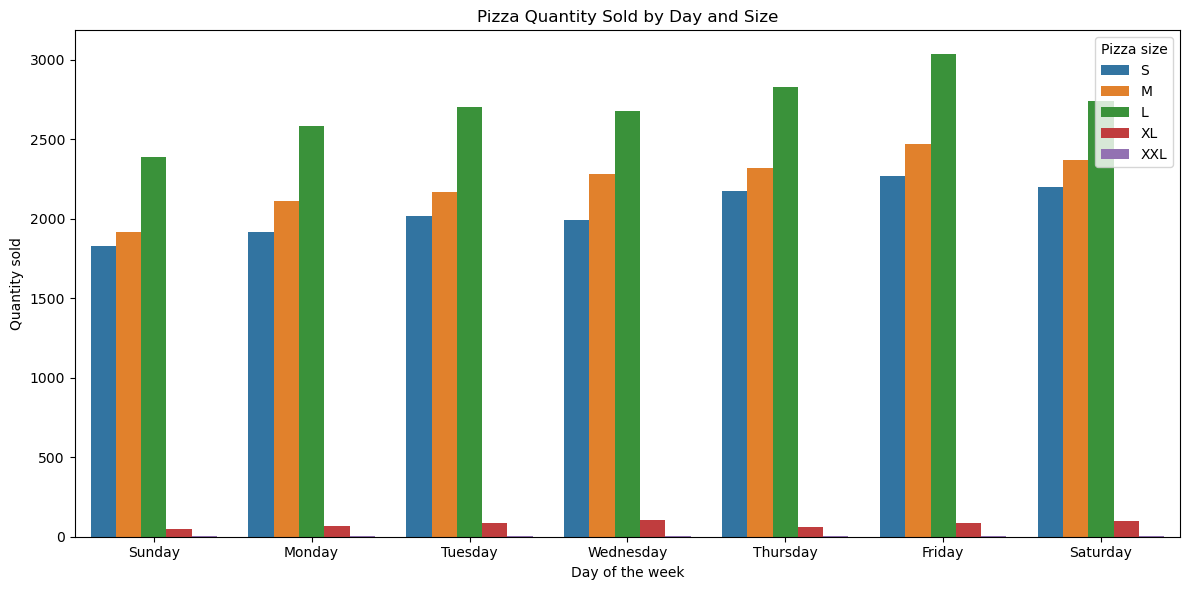

In [80]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=per,
    x='Order_Day',
    y='quantity',
    hue='pizza_size',
    order=weekdays,
    hue_order=['S', 'M', 'L', 'XL', 'XXL']
)
plt.title('Pizza Quantity Sold by Day and Size')
plt.xlabel('Day of the week')
plt.ylabel('Quantity sold')
plt.legend(title='Pizza size')
plt.tight_layout()
plt.show()

In [81]:
df.columns

Index(['pizza_id', 'order_id', 'pizza_name_id', 'quantity', 'order_date',
       'order_time', 'unit_price', 'total_price', 'pizza_size',
       'pizza_category', 'pizza_ingredients', 'pizza_name', 'Order_Day',
       'Order_Month', 'Order_Hour'],
      dtype='object')

In [87]:
data = df.select_dtypes(['int','float'])
data = df.drop(columns=['pizza_id','order_id','pizza_name_id','Order_Hour'
                        ,'Order_Month','Order_Day','pizza_name','pizza_ingredients',
                       'pizza_category','pizza_size' ])
data.columns

Index(['quantity', 'order_date', 'order_time', 'unit_price', 'total_price'], dtype='object')

<Axes: >

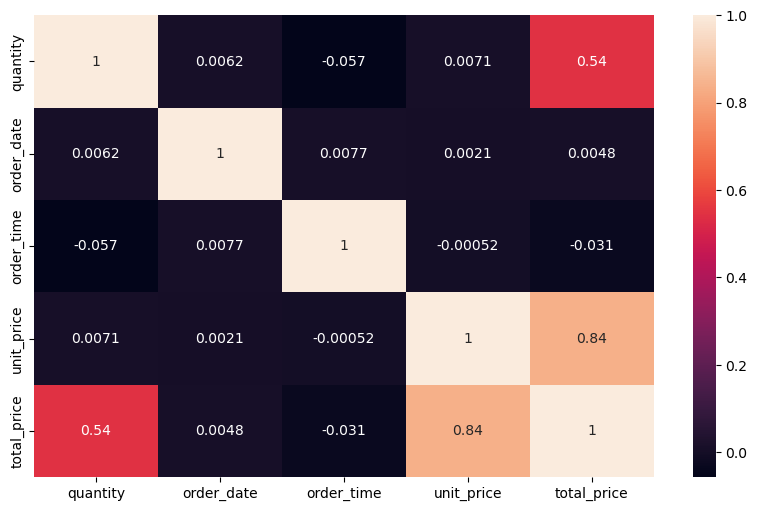

In [88]:
corr_data = data.corr(method='pearson')
plt.figure(figsize=(10,6))
sns.heatmap(corr_data, annot=True)